# Notebook 6 – Multivariate Analysis

# Question

How can we analyze relationships among multiple variables using Multivariate Analysis?

In this notebook, we will analyze:

- Correlation Matrix
- Heatmap
- Pair Plot
- Multiple Feature Relationships
- Feature Interactions
- Numerical Feature Relationships

We will also identify:

- Strong correlations
- Weak correlations
- Negative correlations
- Potential multicollinearity
- Interesting feature relationships

# Question 1

### What is a Correlation Matrix, and how can we use it to understand the relationships between multiple numerical variables?


## Step 1: Understand the concept

A Correlation Matrix shows the relationship between multiple numerical variables.

The correlation value ranges from -1 to +1.

- +1 → Strong positive relationship
- -1 → Strong negative relationship
- 0 → Weak or no linear relationship

A positive correlation means both variables tend to increase together.

A negative correlation means one variable tends to increase when the other decreases.

Correlation Matrix is useful for identifying relationships between multiple features.

## Step 2: Demonstrate the concept

In the Telco Customer Churn dataset, we can compare:

- Tenure
- Monthly Charges
- Total Charges

For example, if Tenure and Total Charges have a high positive correlation, it means customers who stay longer tend to have higher total charges.

This helps us understand relationships between numerical features.

### AI/ML Use

Correlation analysis helps identify related features and can support feature selection before building a machine learning model.


## Step 3: Implementation the concept

In [1]:
# Step 3: Implement

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Convert TotalCharges to numeric

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Select Numerical Features

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Create Correlation Matrix

correlation_matrix = df[numerical_features].corr()

print("Correlation Matrix:")
print(correlation_matrix.round(2))

Correlation Matrix:
                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00


## Code Explanation

- `df[numerical_features]` selects the numerical columns.
- `.corr()` calculates the correlation between the selected variables.
- `.round(2)` displays the values up to two decimal places.

### Expected Insight

The output shows how strongly each numerical feature is related to the other numerical features.

A value closer to +1 indicates a strong positive relationship.

### Why is this important?

Correlation helps us understand feature relationships before applying machine learning algorithms.

# Question 2

### How can a Heatmap be used to visually identify strong, weak, and negative correlations between multiple numerical variables?


## Step 1: Understand the concept

A Heatmap is a visual representation of a Correlation Matrix.

It uses different shades to represent correlation values.

- Strong positive correlation → Higher positive value
- Strong negative correlation → Lower negative value
- Weak correlation → Value close to 0

A Heatmap makes it easier to identify relationships between many numerical features quickly.

## Step 2: Demonstrate the concept

We will create a Heatmap using:

- Tenure
- Monthly Charges
- Total Charges

The correlation values will be displayed inside the Heatmap.

For example, if Tenure and TotalCharges show a high positive correlation, the Heatmap will make this relationship easy to identify.

### AI/ML Use

Heatmaps are useful during EDA to quickly identify highly correlated features and possible multicollinearity.



## Step 3: Implementation the concept

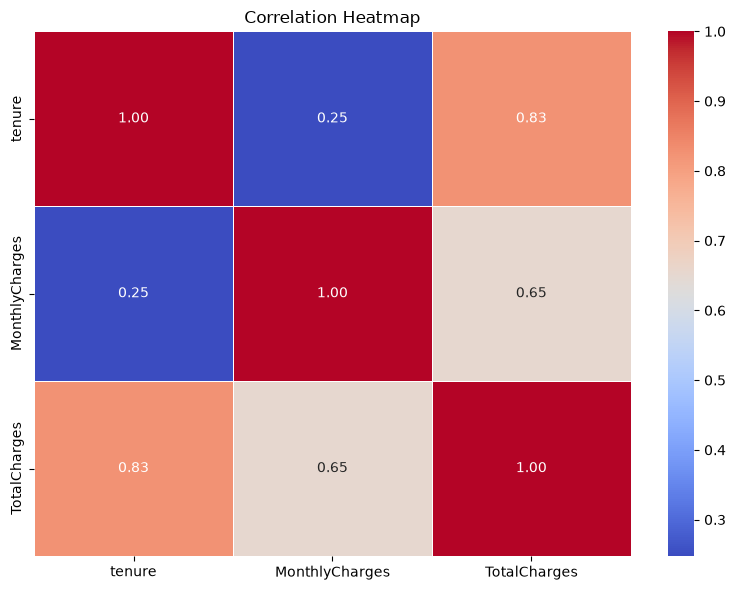

In [2]:
# Step 3: Implement

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Code Explanation

- `sns.heatmap()` creates the Heatmap.
- `annot=True` displays the correlation values.
- `fmt=".2f"` shows values with two decimal places.
- `cmap="coolwarm"` visually separates positive and negative correlations.

### Expected Insight

The Heatmap helps us quickly identify:

- Strong positive relationships
- Strong negative relationships
- Weak relationships

### AI/ML Use

It can help identify redundant features before training a machine learning model.

# Question 3

### How can a Pair Plot be used to study relationships among multiple numerical variables?


## Step 1: Understand the concept

A Pair Plot shows the relationship between every pair of selected numerical variables.

It contains:

- Scatter plots between different variables
- Distribution plots for individual variables

This allows us to study several numerical relationships in one visualization.

## Step 2: Demonstrate the concept

We will use:

- Tenure
- Monthly Charges
- Total Charges

A Pair Plot allows us to observe whether these variables have positive, negative, or weak relationships.

It can also help identify unusual observations or outliers.

### AI/ML Use

Pair Plots help us understand relationships between features before selecting features for machine learning.


## Step 3: Implementation the concept

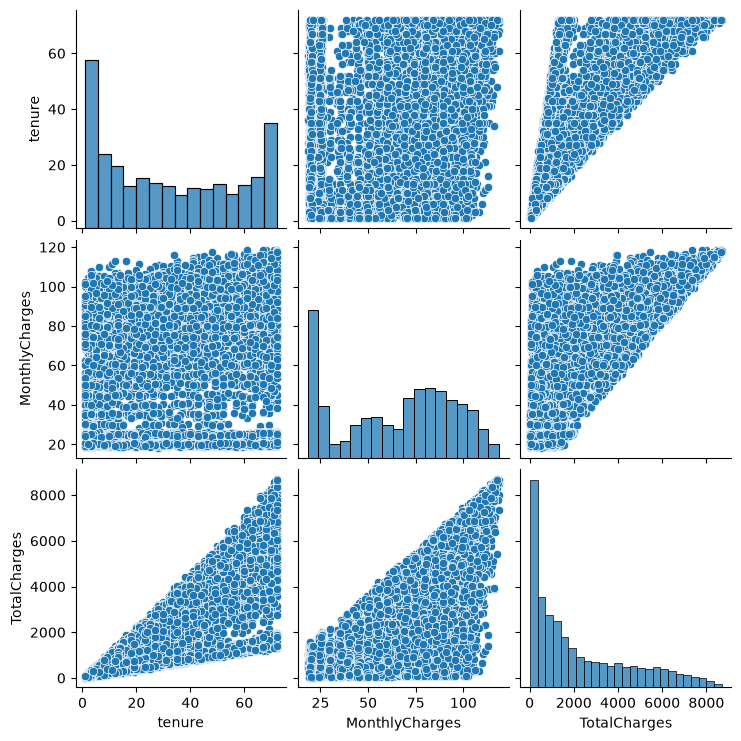

In [3]:


pairplot_data = df[numerical_features].dropna()

sns.pairplot(pairplot_data)

plt.show()

## Code Explanation

- `df[numerical_features]` selects the numerical features.
- `.dropna()` removes rows with missing numerical values.
- `sns.pairplot()` creates scatter plots for every pair of variables.

### Expected Insight

The Pair Plot helps identify:

- Positive relationships
- Negative relationships
- Weak relationships
- Possible outliers
- Distribution patterns

### AI/ML Use

It helps understand feature relationships before machine learning model development.

# Question 4

### How can we analyze relationships among multiple numerical features?


## Step 1: Understand the concept

Multiple Feature Relationship Analysis means studying several variables together instead of analyzing only two variables.

In this dataset, we can study:

- Tenure
- Monthly Charges
- Total Charges

The Correlation Matrix and Pair Plot can help us understand how these features are related.

## Step 2: Demonstrate the concept

For example:

- Tenure may be related to Total Charges.
- Monthly Charges may have some relationship with Total Charges.
- Two features may have a weak relationship.

Studying these relationships together gives a better understanding of the dataset.

### AI/ML Use

Multiple feature analysis helps identify useful features and redundant features before model training.


## Step 3: Implementation the concept

In [4]:


for i in range(len(numerical_features)):
    for j in range(i + 1, len(numerical_features)):

        feature1 = numerical_features[i]
        feature2 = numerical_features[j]

        correlation = df[feature1].corr(df[feature2])

        print(
            f"{feature1} vs {feature2}: "
            f"{correlation:.2f}"
        )

tenure vs MonthlyCharges: 0.25
tenure vs TotalCharges: 0.83
MonthlyCharges vs TotalCharges: 0.65


## Code Explanation

The nested loops compare every unique pair of numerical features.

For each pair:

- The two features are selected.
- Their correlation is calculated.
- The correlation value is displayed.

### Expected Insight

This helps identify which feature pairs have stronger or weaker relationships.

### AI/ML Use

It helps understand which features may contain similar information.

# Question 5

### How can Feature Interactions help us understand customer behavior?


## Step 1: Understand the concept

Feature Interaction means studying the combined effect or relationship of multiple features.

A relationship that is not obvious from one feature alone may become clearer when two or more features are considered together.

For example:

- Contract
- Tenure
- Churn

can be studied together to understand customer behavior.

## Step 2: Demonstrate the concept

Suppose we compare the average Tenure for different Contract types and Churn status.

This can help us understand whether customer tenure differs between customers who stayed and customers who left.

### AI/ML Use

Feature interactions can provide useful information for predicting customer churn.


## Step 3: Implementation the concept

In [5]:


feature_interaction = (
    df.groupby(
        ["Contract", "Churn"]
    )["tenure"]
    .mean()
    .reset_index()
)

print("Average Tenure by Contract and Churn:")
print(feature_interaction.round(2))

Average Tenure by Contract and Churn:
         Contract Churn  tenure
0  Month-to-month    No   21.03
1  Month-to-month   Yes   14.02
2        One year    No   41.67
3        One year   Yes   44.96
4        Two year    No   56.60
5        Two year   Yes   61.27


## Code Explanation

- `groupby()` groups customers based on Contract and Churn.
- `.mean()` calculates the average tenure for each group.
- `reset_index()` converts the result into a DataFrame.

### Expected Insight

We can compare the average tenure of customers who stayed and customers who churned within each contract type.

### AI/ML Use

This can reveal useful customer behavior patterns for churn prediction.

# Question 6

### How can we identify strong, weak, and negative relationships between numerical features?


## Step 1: Understand the concept

Correlation strength can be used to classify numerical feature relationships.

For this analysis, we can use:

- Strong Positive → 0.70 or above
- Strong Negative → -0.70 or below
- Weak → Between -0.30 and +0.30
- Moderate → Other values

These are practical guidelines for interpreting correlation.

## Step 2: Demonstrate the concept

We will examine the correlation between:

- Tenure
- Monthly Charges
- Total Charges

The correlation value will tell us whether each pair has a strong, moderate, weak, positive, or negative relationship.

### AI/ML Use

This helps us understand feature relationships and identify potentially redundant features.


## Step 3: Implementation the concept

In [6]:


correlation_matrix = df[numerical_features].corr()

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):

        feature1 = correlation_matrix.columns[i]
        feature2 = correlation_matrix.columns[j]

        value = correlation_matrix.iloc[i, j]

        if value >= 0.70:
            relationship = "Strong Positive"
        elif value <= -0.70:
            relationship = "Strong Negative"
        elif abs(value) < 0.30:
            relationship = "Weak"
        else:
            relationship = "Moderate"

        print(
            f"{feature1} vs {feature2}: "
            f"{value:.2f} → {relationship}"
        )

tenure vs MonthlyCharges: 0.25 → Weak
tenure vs TotalCharges: 0.83 → Strong Positive
MonthlyCharges vs TotalCharges: 0.65 → Moderate


## Code Explanation

The code checks every unique pair of numerical features.

Based on the correlation value, it classifies the relationship as:

- Strong Positive
- Strong Negative
- Weak
- Moderate

### Expected Insight

The output tells us the strength and direction of the relationship between each numerical feature pair.

# Question 7

### How can we identify potential multicollinearity between numerical features?


## Step 1: Understand the concept

Multicollinearity occurs when two or more independent features are highly correlated.

For example, if two features have a correlation close to +1 or -1, they may contain similar information.

This can make some machine learning models harder to interpret.

A correlation value of 0.80 or higher in absolute value can be used as a warning level for potential multicollinearity.

This is only a practical guideline. Further analysis such as VIF should be used before deciding to remove a feature.

## Step 2: Demonstrate the concept

We will check the numerical features:

- Tenure
- Monthly Charges
- Total Charges

If any pair has an absolute correlation of 0.80 or above, we will flag it as potentially highly correlated.

### AI/ML Use

Detecting multicollinearity can help reduce redundant features and improve model interpretability.


## Step 3: Implementation the concept

In [7]:


threshold = 0.80

correlation_matrix = df[numerical_features].corr()

print("Potential Multicollinearity:\n")

found = False

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):

        feature1 = correlation_matrix.columns[i]
        feature2 = correlation_matrix.columns[j]

        value = correlation_matrix.iloc[i, j]

        if abs(value) >= threshold:
            print(
                f"{feature1} ↔ {feature2}: "
                f"{value:.2f}"
            )
            found = True

if not found:
    print("No feature pair crossed the 0.80 threshold.")

Potential Multicollinearity:

tenure ↔ TotalCharges: 0.83


## Code Explanation

- `threshold = 0.80` sets the warning level.
- `abs(value)` checks both positive and negative high correlations.
- If the absolute correlation is 0.80 or above, the feature pair is displayed.

### Expected Insight

Highly correlated feature pairs are flagged for further investigation.

### Important Note

A high correlation does not automatically mean that a feature should be removed.

We should consider:

- VIF
- Domain knowledge
- Model performance
- Feature importance

# Question 8

# Identify the strong correlations between numerical features.

## Step 1: Understand the concept

A strong correlation means two numerical features have a high positive or negative relationship.

For this analysis, we consider a correlation value of:

- +0.70 or above → Strong Positive
- -0.70 or below → Strong Negative

Strong correlations can show that two features change together.

## Step 2: Demonstrate the concept

In the Telco dataset, we compare:

- Tenure
- MonthlyCharges
- TotalCharges

We will identify feature pairs with correlation values of 0.70 or higher in absolute value.


## Step 3: Implementation the concept

In [8]:
# Identify Strong Correlations

correlation_matrix = df[numerical_features].corr()

print("Strong Correlations:\n")

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):

        feature1 = correlation_matrix.columns[i]
        feature2 = correlation_matrix.columns[j]
        value = correlation_matrix.iloc[i, j]

        if abs(value) >= 0.70:
            print(f"{feature1} vs {feature2}: {value:.2f}")

Strong Correlations:

tenure vs TotalCharges: 0.83


# Question 9

# Identify the weak correlations between numerical features.

## Step 1: Understand the concept

A weak correlation means two numerical features have little linear relationship.

For this analysis:

- Correlation between -0.30 and +0.30 → Weak correlation

Weak correlation means changes in one feature do not strongly explain changes in another feature.

## Step 2: Demonstrate the concept

We compare the numerical features and identify pairs whose absolute correlation value is less than 0.30.


## Step 3: Implementation the concept

In [9]:
# Identify Weak Correlations

print("Weak Correlations:\n")

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):

        feature1 = correlation_matrix.columns[i]
        feature2 = correlation_matrix.columns[j]
        value = correlation_matrix.iloc[i, j]

        if abs(value) < 0.30:
            print(f"{feature1} vs {feature2}: {value:.2f}")

Weak Correlations:

tenure vs MonthlyCharges: 0.25


# Question 10

# Identify the negative correlations between numerical features.

## Step 1: Understand the concept

A negative correlation means that when one feature increases, the other feature tends to decrease.

A correlation value below 0 represents a negative relationship.

The closer the value is to -1, the stronger the negative relationship.

## Step 2: Demonstrate the concept

We will check the correlation matrix and identify all feature pairs with correlation values below 0.


## Step 3: Implementation the concept

In [10]:
# Identify Negative Correlations

print("Negative Correlations:\n")

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):

        feature1 = correlation_matrix.columns[i]
        feature2 = correlation_matrix.columns[j]
        value = correlation_matrix.iloc[i, j]

        if value < 0:
            print(f"{feature1} vs {feature2}: {value:.2f}")

Negative Correlations:



# Question 11

# Identify potential multicollinearity between numerical features.

## Step 1: Understand the concept

Multicollinearity occurs when two or more features are highly correlated with each other.

A high correlation between independent features may mean that they contain similar information.

For this analysis, we use an absolute correlation value of 0.80 or above as a warning level.

## Step 2: Demonstrate the concept

We check all numerical feature pairs.

If the absolute correlation is 0.80 or higher, the pair is identified as potentially multicollinear.

This does not automatically mean that a feature should be removed.


## Step 3: Implementation the concept

In [11]:
# Identify Potential Multicollinearity

threshold = 0.80

print("Potential Multicollinearity:\n")

found = False

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):

        feature1 = correlation_matrix.columns[i]
        feature2 = correlation_matrix.columns[j]
        value = correlation_matrix.iloc[i, j]

        if abs(value) >= threshold:
            print(f"{feature1} ↔ {feature2}: {value:.2f}")
            found = True

if not found:
    print("No feature pair crossed the 0.80 threshold.")

Potential Multicollinearity:

tenure ↔ TotalCharges: 0.83


# Question 12

# Identify interesting relationships between features in the dataset.

## Step 1: Understand the concept

An interesting feature relationship is a useful pattern found between two or more features.

These relationships may help us understand customer behavior.

For example:

- Tenure and TotalCharges
- Contract and Tenure
- Contract and Churn
- MonthlyCharges and TotalCharges

## Step 2: Demonstrate the concept

We can use correlation analysis and feature interaction analysis to identify useful relationships.

For example, customers with longer tenure may have higher TotalCharges.

We can also compare Contract, Tenure, and Churn together to understand customer behavior.

### AI/ML Use

These relationships can provide useful features and insights for customer churn prediction.


## Step 3: Implementation the concept

In [12]:
# Identify Interesting Feature Relationships

print("Interesting Feature Relationships:\n")

tenure_total = df["tenure"].corr(df["TotalCharges"])
monthly_total = df["MonthlyCharges"].corr(df["TotalCharges"])

print(f"Tenure vs TotalCharges: {tenure_total:.2f}")
print(f"MonthlyCharges vs TotalCharges: {monthly_total:.2f}")

print("\nAverage Tenure by Contract and Churn:")

interaction = (
    df.groupby(["Contract", "Churn"])["tenure"]
    .mean()
    .reset_index()
)

print(interaction.round(2))

Interesting Feature Relationships:

Tenure vs TotalCharges: 0.83
MonthlyCharges vs TotalCharges: 0.65

Average Tenure by Contract and Churn:
         Contract Churn  tenure
0  Month-to-month    No   21.03
1  Month-to-month   Yes   14.02
2        One year    No   41.67
3        One year   Yes   44.96
4        Two year    No   56.60
5        Two year   Yes   61.27
